# 13 · Idea D — Curve Momentum

**状态：** documented negative/mixed。full-sample gross 很弱，all-in net 为负；test gross 也为负。

本 notebook 只负责一个 idea。PnL、持仓和 overall Sharpe 都来自 v2 正式口径；
历史 v1 内容不在这里重复，见 `docs/HANDOFF.md` 和 `docs/notebook_history.md`。


## 1. 约定 / Conventions

- 正式结果使用 v2 holdings-based simulator（D-019）。
- 口径：`d=5`、`k=5`、`min_adv=100`、USD 10m capital、equal-notional、
  三层成本（half-spread / fees / impact），见 D-018。
- PnL 曲线：`F.nav_by_cost_layer`，gross 加上三层成本，阴影是 2016 年起的
  post-hoc test sample。
- Overall Sharpe：full sample 1986–2026 的 **all-in net** 日收益，rf=0，
  252 天年化；每个 notebook 只报这一个 Sharpe。
- 持仓热力图：方向取最近到期腿（蓝=多，橙=空，白=空仓），大小是该品种的
  gross notional / capital；下图是组合 gross exposure 和年化换手。


## 2. 环境与数据 / Setup


In [1]:
import sys
import logging
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config, figures as F, plotstyle as ps, report, v2_rerun

logging.getLogger("fontTools").setLevel(logging.ERROR)
ps.use()
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
OUT = config.OUTPUT_DIR / "v2_rerun"
OUT.mkdir(parents=True, exist_ok=True)
ROOT_ORDER = (
    rank[["root", "sector"]]
    .drop_duplicates()
    .sort_values(["sector", "root"])["root"]
    .tolist()
)
rank.shape


(1013664, 23)

## 3. 运行 / Run


In [2]:
item = v2_rerun.run_strategy("d", rank)
v2_rerun.save_strategy(item, OUT)
res = item["result"]
print("saved:", OUT / "d_performance.csv", OUT / "d_root.csv")


saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/.claude/worktrees/d-signal-validity/output/v2_rerun/d_performance.csv /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/.claude/worktrees/d-signal-validity/output/v2_rerun/d_root.csv


## 4. Full-sample 总览 / Headline


In [3]:
full = item["performance"].xs("full", level="period").set_index("layer")
display(
    full[["ann_ret_pct", "ann_vol_pct", "max_dd_pct", "turnover_x"]]
    .round(3)
    .rename(columns={
        "ann_ret_pct": "Ann. ret (%)",
        "ann_vol_pct": "Ann. vol (%)",
        "max_dd_pct": "Max DD (%)",
        "turnover_x": "Turnover (x/yr)",
    })
)
print(f"Overall Sharpe (full sample, all-in net): {report.overall_sharpe(res):+.3f}")


,Ann. ret (%),Ann. vol (%),Max DD (%),Turnover (x/yr)
layer,,,,
gross,0.219,0.881,-5.510,22.078
- half-spread,-0.074,0.883,-7.338,22.078
- fees,-0.202,0.884,-11.375,22.078
- impact (all),-1.418,0.931,-60.255,22.078


Overall Sharpe (full sample, all-in net): -1.523


## 5. PnL 曲线 / Cumulative PnL


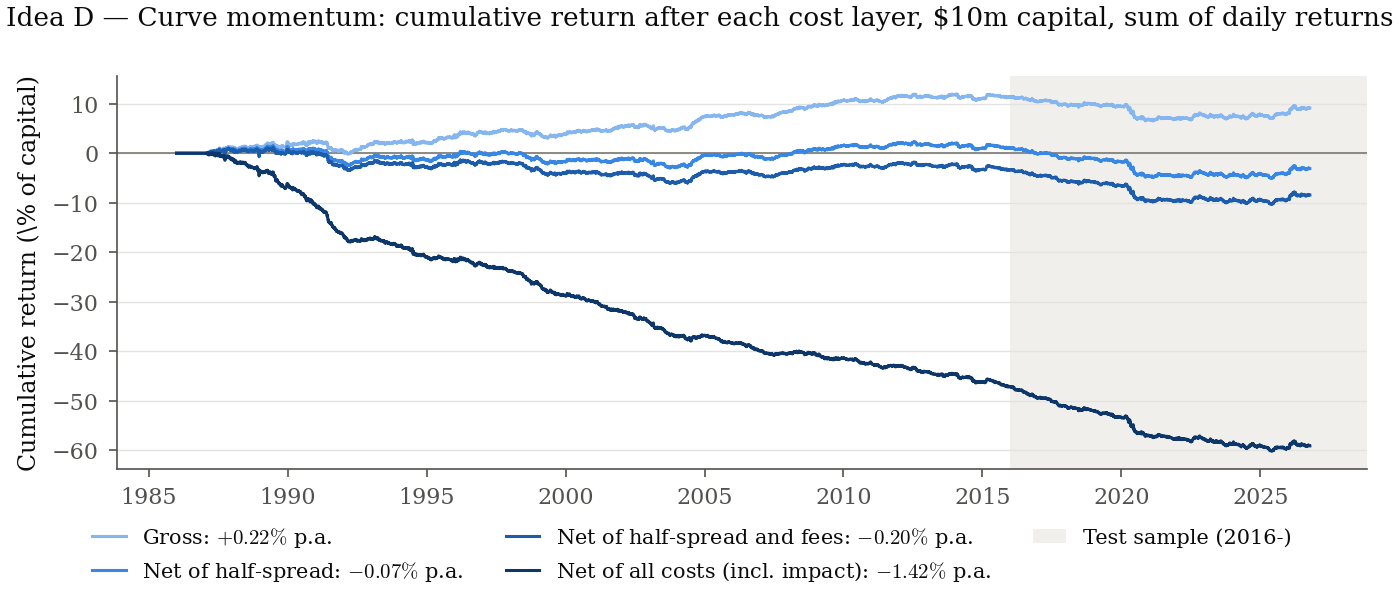

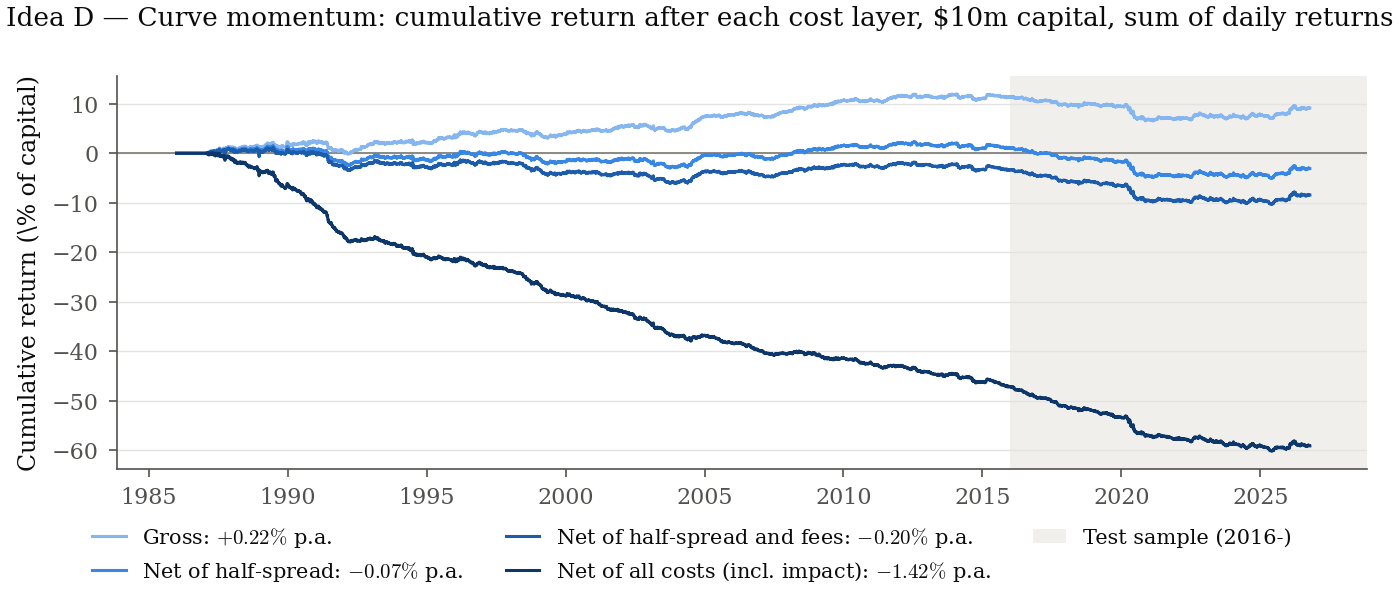

In [4]:
fig = F.nav_by_cost_layer(res, "Idea D — Curve momentum")
ps.save(fig, "idea_d_pnl")
display(fig)


## 6. 持仓变化 / Positions


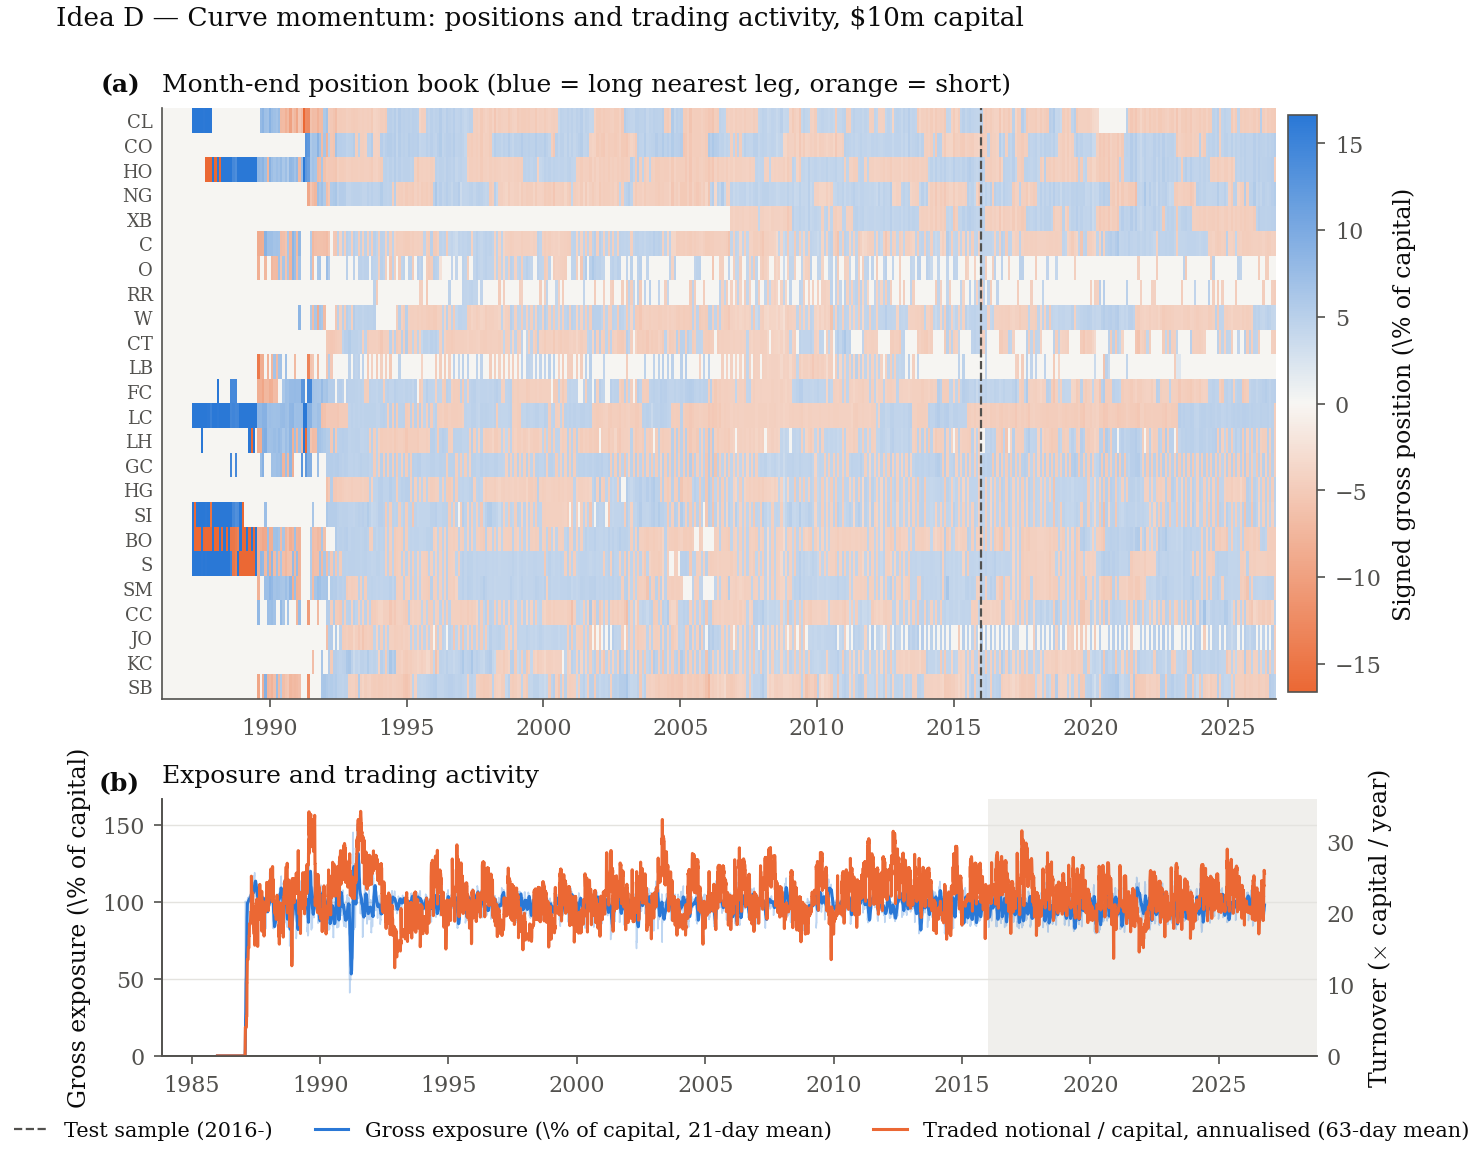

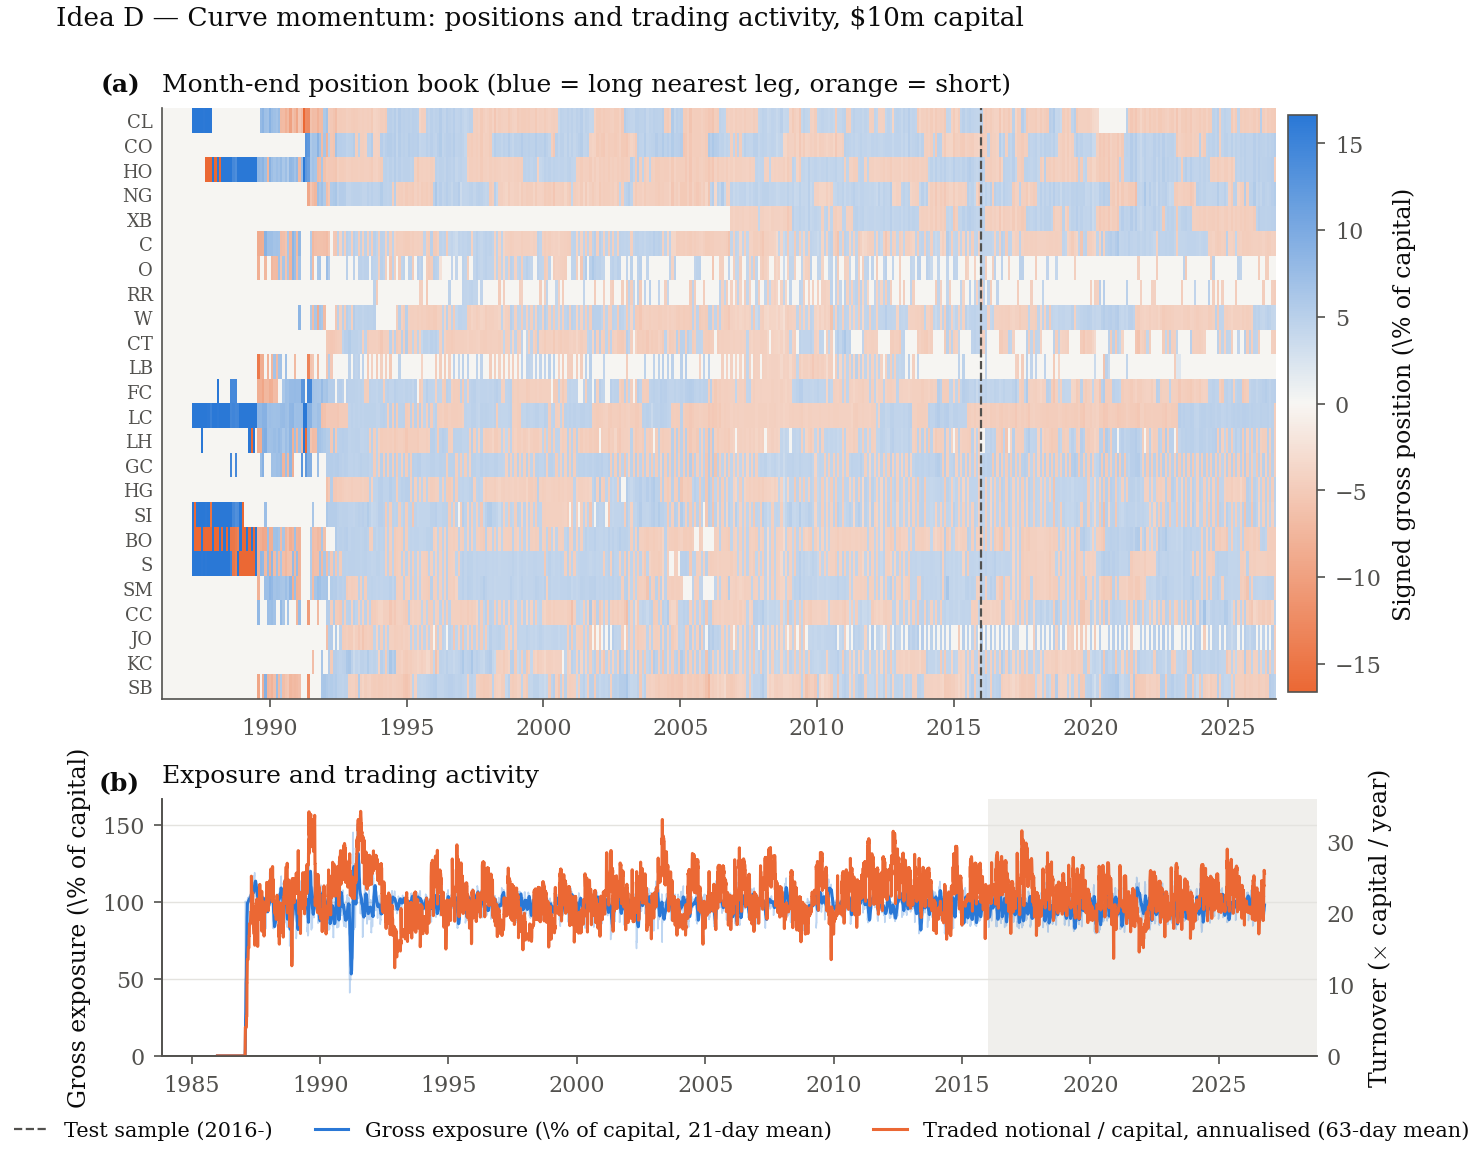

In [5]:
panel = F.position_panel(res, root_order=ROOT_ORDER)
panel.to_csv(OUT / "d_positions_month_end.csv")
fig = F.positions(res, "Idea D — Curve momentum", root_order=ROOT_ORDER)
ps.save(fig, "idea_d_positions")
display(fig)


## 7. D signal validity

这一节把 D 当作一个 **signal** 来检验，而不是一个 trading strategy：不看成本，不看 Sharpe，只问 score 对未来 spread return 有没有信息、信息在哪个 horizon、是否独立于 static / A / C、是否稳定。

主 spec 仍是 D-013（12m formation / N=2 main pair / monthly / sign / D=5 / 不筛流动性），不做参数扫描。所有 forward return 从 **t+1** 开始；same-close 只作为 timing 对照。

In [6]:
from src import d_validity
import matplotlib.pyplot as plt

OUT_VALID = config.OUTPUT_DIR / "d_validity"
OUT_VALID.mkdir(parents=True, exist_ok=True)

panel = d_validity.build_d_panel(rank)
print("panel rows:", len(panel), "roots:", panel["root"].nunique())
coverage = (
    panel.groupby("root")
    .agg(
        n_signal=("date", "size"),
        first=("date", "min"),
        last=("date", "max"),
        fwd_1m=("fwd_1m", lambda s: s.notna().mean()),
        fwd_3m=("fwd_3m", lambda s: s.notna().mean()),
        fwd_6m=("fwd_6m", lambda s: s.notna().mean()),
        fwd_12m=("fwd_12m", lambda s: s.notna().mean()),
        c_z_missing=("c_z", lambda s: s.isna().mean()),
    )
)
num_cols = coverage.select_dtypes("number").columns
display(coverage.assign(**{c: coverage[c].round(3) for c in num_cols}))

panel rows: 10978 roots: 24


,n_signal,first,last,fwd_1m,fwd_3m,fwd_6m,fwd_12m,c_z_missing
root,,,,,,,,
BO,478,1987-01-30,2026-10-05,0.998,0.994,0.987,0.975,0.000
C,478,1987-01-30,2026-10-05,0.998,0.994,0.987,0.975,0.000
CC,467,1987-01-30,2026-10-05,0.994,0.987,0.979,0.966,0.011
CL,466,1987-01-30,2026-10-05,0.994,0.987,0.974,0.948,0.006
CO,449,1989-06-30,2026-10-05,0.998,0.993,0.987,0.973,0.000
CT,478,1987-01-30,2026-10-05,0.996,0.994,0.987,0.975,0.008
FC,478,1987-01-30,2026-10-05,0.998,0.994,0.987,0.975,0.002
GC,478,1987-01-30,2026-10-05,0.996,0.994,0.987,0.975,0.002
HG,443,1989-12-29,2026-10-05,0.995,0.993,0.986,0.973,0.002


In [7]:
validity = d_validity.run_all(panel, n_boot=2000, n_shuffle=1000, seed=0)
print("validity tables:", ", ".join(validity.keys()))

validity tables: ic, hit, quantiles, regression, incremental, stability, placebo, horizon


### 7a. 核心预测力

Per-root rank IC（raw score vs 1-month forward return）、sign hit rate、expanding quintile。IC 的 t 是 Newey-West（lag = 1 month）；CI/p 是 6-month moving-block bootstrap。`ALL` 行是 root 等权均值，root 之间并不独立。

In [8]:
ic_table = validity["ic"].set_index("root")
display(ic_table[["ic", "ci_lo", "ci_hi", "p_value", "n", "t_nw", "p_fdr"]].round(3))
all_ic = ic_table.loc["ALL"]
print(
    f"ALL: mean IC {all_ic['ic']:.3f}, median {all_ic['median_ic']:.3f}, "
    f"{all_ic['frac_positive']:.0%} roots positive"
)
display(validity["hit"].set_index("root").round(3))
display(validity["quantiles"].round(2))

,ic,ci_lo,ci_hi,p_value,n,t_nw,p_fdr
root,,,,,,,
BO,0.132,0.027,0.227,0.010,477,2.514,0.060
C,0.025,-0.067,0.126,0.558,477,0.502,0.812
CC,0.024,-0.074,0.121,0.677,464,0.476,0.812
CL,0.032,-0.065,0.105,0.665,463,0.619,0.812
CO,0.013,-0.080,0.103,0.769,448,0.263,0.815
CT,-0.047,-0.145,0.039,0.236,476,-0.965,0.478
FC,0.048,-0.041,0.135,0.314,477,1.037,0.580
GC,0.071,-0.044,0.179,0.230,476,1.506,0.478
HG,0.114,0.016,0.220,0.019,441,2.120,0.088


ALL: mean IC 0.049, median 0.032, 79% roots positive


,hit_rate,ci_lo,ci_hi,p_value,n
root,,,,,
BO,0.547,0.497,0.591,0.065,477
C,0.518,0.476,0.562,0.373,477
CC,0.515,0.468,0.562,0.585,464
CL,0.518,0.469,0.559,0.495,463
CO,0.533,0.491,0.574,0.138,448
CT,0.508,0.460,0.555,0.877,476
FC,0.530,0.484,0.572,0.224,477
GC,0.557,0.504,0.605,0.038,476
HG,0.592,0.537,0.642,0.000,441


,bin,mean_bps,t_nw,n
0,1,7.25,1.01,1746
1,2,5.05,1.09,2074
2,3,11.95,3.05,2229
3,4,21.18,2.22,1931
4,5,16.70,2.08,1514


### 7b. Horizon profile

同一个 score 对 1/3/6/12 个月 forward return 的 IC 和 sign-rule 收益。若 IC 随 horizon 上升，说明信息是慢变量；若只活在 1 个月，说明是短期事件。

,horizon_months,ic_mean,ic_median,frac_positive,hit_rate,mean_bps,t_nw,n_dates
0,1,0.049,0.032,0.792,0.525,4.350,3.693,528
1,3,0.140,0.108,0.833,0.563,15.162,5.461,527
2,6,0.173,0.133,0.917,0.577,26.087,4.946,524
3,12,0.190,0.157,0.833,0.589,43.669,3.405,517


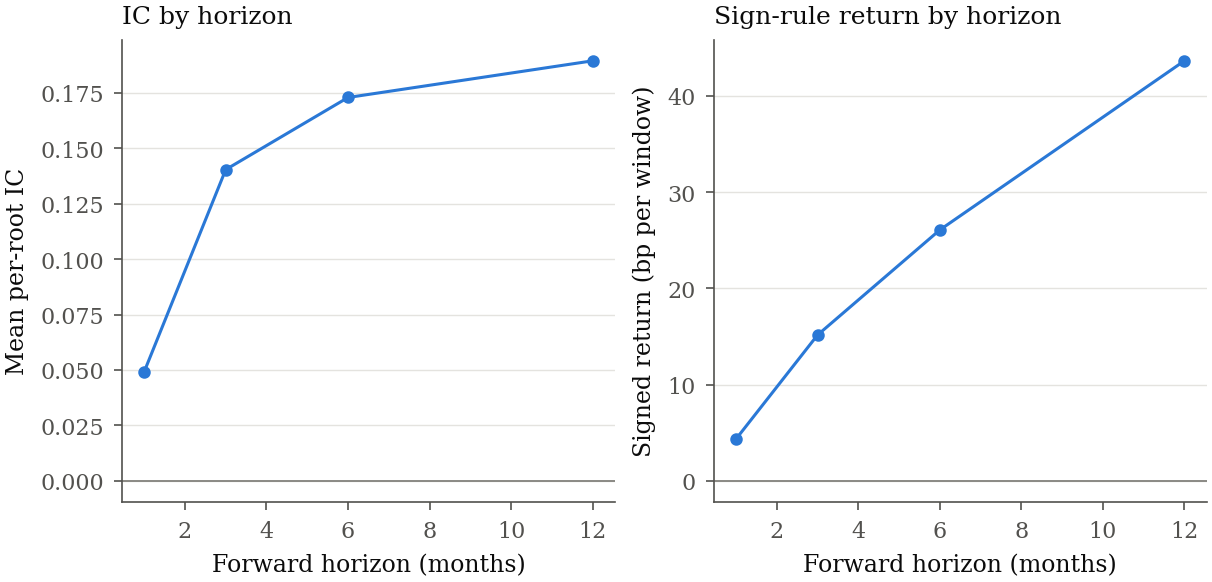

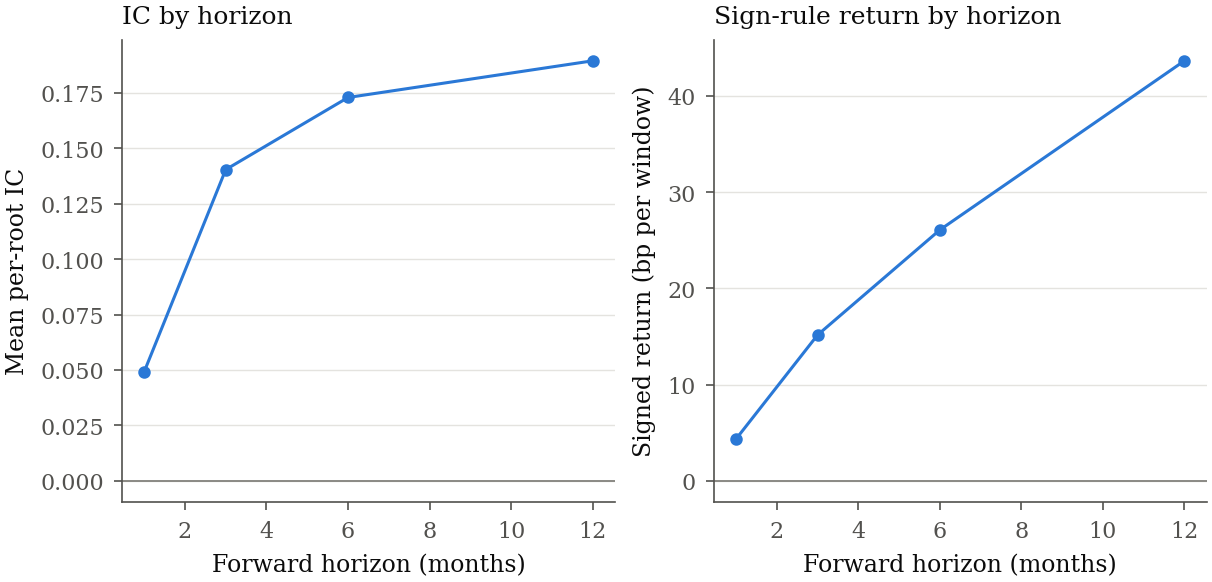

In [9]:
display(validity["horizon"].round(3))
h = validity["horizon"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(ps.FULL_WIDTH, 3.0))
a1.plot(h["horizon_months"], h["ic_mean"], marker="o", color=ps.BLUE)
ps.zero_line(a1)
a1.set_xlabel("Forward horizon (months)")
a1.set_ylabel("Mean per-root IC")
a1.set_title("IC by horizon")
a2.plot(h["horizon_months"], h["mean_bps"], marker="o", color=ps.BLUE)
ps.zero_line(a2)
a2.set_xlabel("Forward horizon (months)")
a2.set_ylabel("Signed return (bp per window)")
a2.set_title("Sign-rule return by horizon")
ps.save(fig, "d_validity_horizon")
display(fig)

### 7c. 独立性 / 增量信息

Nested per-root regressions：static +1 → +D → +A carry → +C z。`delta_adj_r2` 是每一步的 adjusted R² 增量；`residual_ic` 是把 D score 对 A/C/static 残差化之后的 IC。`static` 表比较 always-long、long/short 两侧和 timing spread。 `ALL` 行的 `p_value` 是 per-root p 的中位数，不是 aggregate test；主要看 per-root 分布和 `frac_positive`。

In [10]:
inc = validity["incremental"]
display(inc["per_root"].tail(1).round(4))
display(inc["deltas"].loc[inc["deltas"]["root"].eq("ALL")].round(4))
display(
    inc["deltas"].loc[inc["deltas"]["root"].ne("ALL")]
    .groupby("step")
    .agg(
        mean=("delta_adj_r2", "mean"),
        median=("delta_adj_r2", "median"),
        frac_positive=("delta_adj_r2", lambda s: (s > 0).mean()),
    )
    .round(4)
)
display(inc["residual_ic"].tail(1).round(4))
display(inc["static"].tail(1).round(3))

,root,adj_static,adj_+D,adj_+A,adj_+C,r2_static,r2_+D,r2_+A,r2_+C,n
24,ALL,-0.0,0.0069,0.0143,0.0158,-0.0,0.0092,0.0188,0.0225,10897


,root,step,delta_adj_r2,ci_lo,ci_hi,p_value,n
72,ALL,static -> +D,0.0069,-0.0018,0.0484,0.6420,10897
73,ALL,+D -> +A,0.0074,-0.0016,0.0556,0.5685,10897
74,ALL,+A -> +C,0.0015,-0.0021,0.0198,0.7570,10897


,mean,median,frac_positive
step,,,
+A -> +C,0.0015,-0.0002,0.3750
+D -> +A,0.0074,0.0024,0.6250
static -> +D,0.0069,0.0007,0.5417


,root,ic_residual,ic_gain,ci_lo,ci_hi,p_value,frac_positive_gain
24,ALL,0.0659,0.0162,NaN,NaN,NaN,0.75


,root,static_mean_bps,long_mean_bps,short_mean_bps,timing_spread_bps,r2,n
24,ALL,11.136,15.851,4.631,11.221,0.006,10897


### 7d. 稳定性

固定年代、carry 状态、spread-return 波动三分位；以及 36 个月 rolling IC 的正收益比例。high-vol 分组用 expanding 三分位，避免 look-ahead。

,group_type,group,ic_mean,ic_median,frac_positive,n_roots,n_obs
0,decade,1986-1999,0.013,0.007,0.609,23,3383
1,decade,2000-2009,0.061,0.060,0.625,24,2785
2,decade,2010-2026,0.051,0.023,0.708,24,4766
3,carry,backwardation,0.022,0.025,0.591,22,3393
4,carry,contango,0.069,0.078,0.708,24,7541
5,vol,high,-0.007,-0.011,0.458,24,2813
6,vol,low,0.079,0.061,0.833,24,4862
7,vol,mid,0.033,0.031,0.667,24,2707


,window_months,positive_share,n_dates
0,36,0.39,441


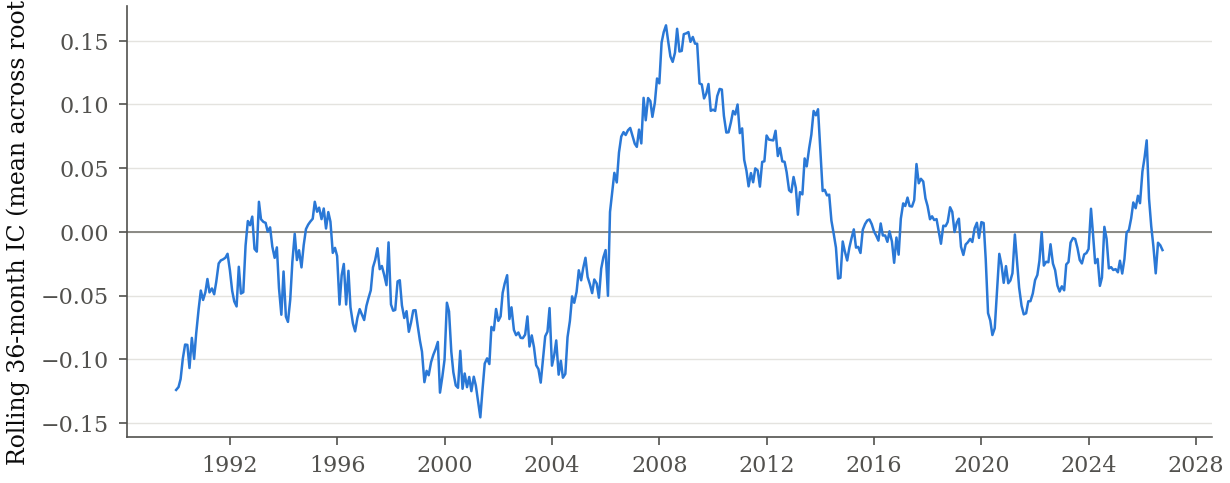

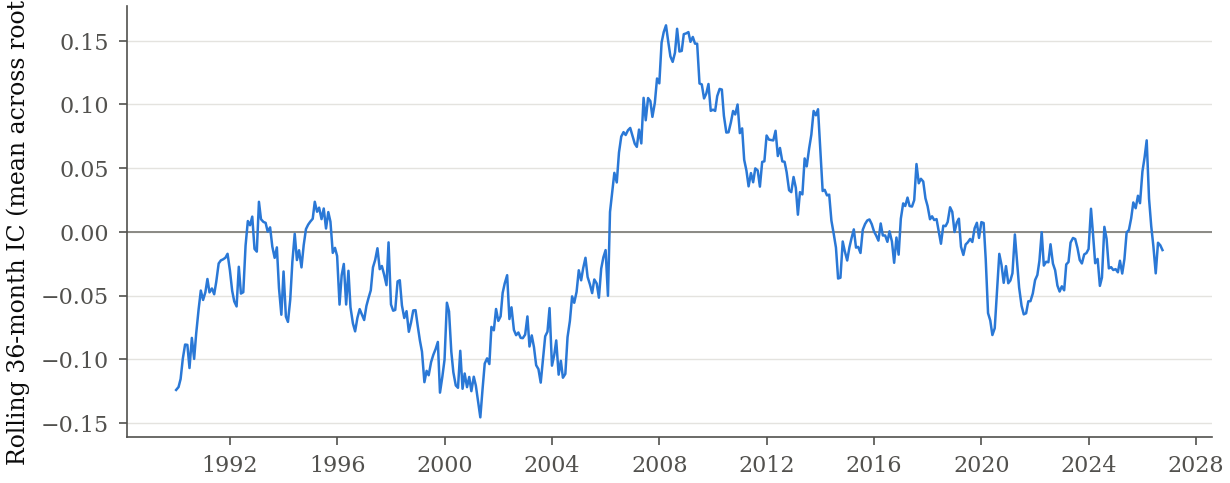

In [11]:
display(validity["stability"]["groups"].round(3))
display(validity["stability"]["rolling_table"].round(3))
rolling = validity["stability"]["rolling"]
fig, ax = plt.subplots(figsize=(ps.FULL_WIDTH, 2.8))
ax.plot(rolling.index, rolling.values, color=ps.BLUE, lw=0.9)
ps.zero_line(ax)
ax.set_ylabel("Rolling 36-month IC (mean across roots)")
ps.save(fig, "d_validity_rolling_ic")
display(fig)

### 7e. Placebo / falsification

sign flip 检验方向；within-root 6-month block shuffle 给出 null 分布；lag 1/3/6/12 个月看衰减；future-score lead 24 个月是 look-ahead 检查。

,test,ic_mean,p_value,n_roots
0,actual,0.0492,NaN,24
1,sign_flip,-0.0492,NaN,24
2,block_shuffle,0.0492,0.0,24
3,max_abs_ic,0.2525,0.0,24


,shift_months,label,ic_mean,n_roots
0,1,lag_1m,0.0155,24
1,3,lag_3m,0.0144,24
2,6,lag_6m,0.0176,24
3,12,lag_12m,0.0117,24
4,-24,future_score_lead_24m,0.0279,24


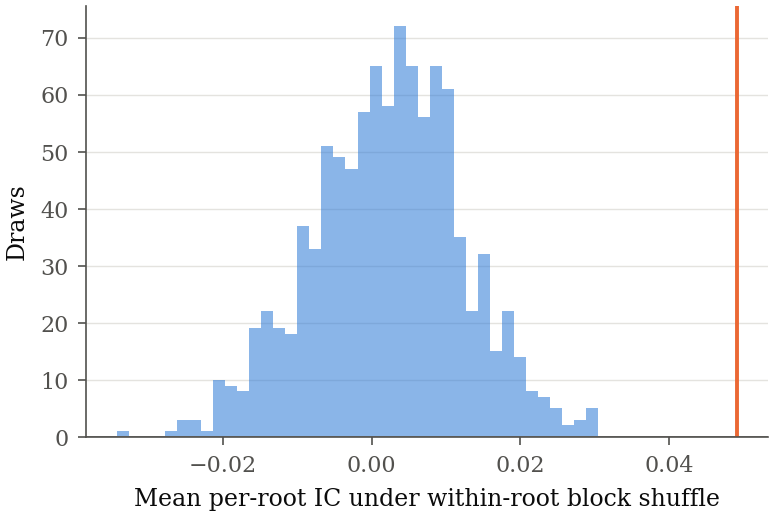

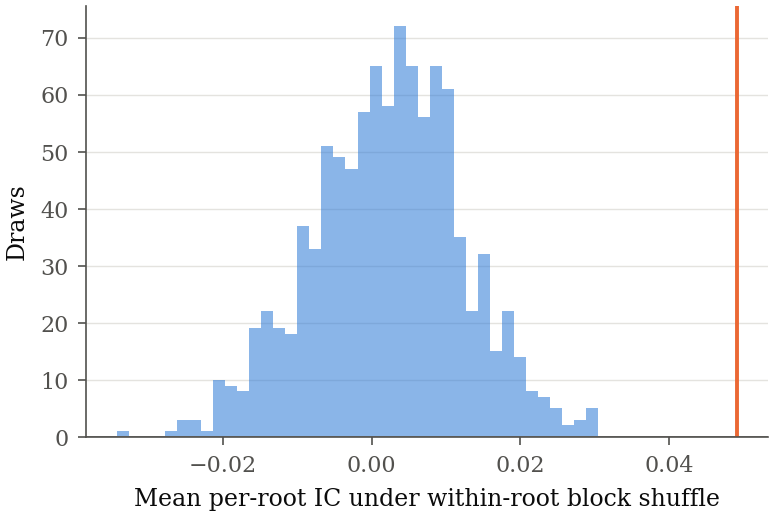

In [12]:
display(validity["placebo"]["summary"].round(4))
display(validity["placebo"]["lag"].round(4))
null = validity["placebo"]["null_mean"]
fig, ax = plt.subplots(figsize=(ps.SINGLE_COL + 1.0, 2.8))
ax.hist(null, bins=40, color=ps.BLUE, alpha=0.55)
ax.axvline(validity["placebo"]["actual_mean"], color=ps.ORANGE, lw=1.4)
ps.zero_line(ax)
ax.set_xlabel("Mean per-root IC under within-root block shuffle")
ax.set_ylabel("Draws")
ps.save(fig, "d_validity_placebo")
display(fig)

In [13]:
d_validity.save_tables(validity, OUT_VALID)
coverage.to_csv(OUT_VALID / "coverage.csv")
print("saved:", OUT_VALID)

saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/.claude/worktrees/d-signal-validity/output/d_validity


## 8. 解读 / Reading

**Trading result（v2 official）：** D 仍是 documented negative/mixed baseline：full-sample gross 很弱，all-in net 为负，2016–2026 test gross 也为负。这一结论不变。

**Signal-validity result（不看成本）：** D 的 raw score 在 1 个月 forward 上有很小的正 IC（约 0.05，NW t ≈ 3.5，约 80% root 为正），但：

- **显著性是集中的**：FDR 后只有 2/24 个 root 的 1m IC 显著（LC、W），nominal p<0.05 也只有 7/24；aggregate CI 排除 0，但证据主要来自少数 root。
- IC 随 horizon 变长而上升（3/6/12 个月约 0.14/0.17/0.19），说明信息是慢变量，不是 1 个月事件。
- expanding quintile 不单调：最高分位并不比次高分位更好，说明 score 的 magnitude 关系不稳。
- 稳定性有限：1986–1999 很弱，high-vol 状态为负，rolling 36 个月 IC 只有约 39% 为正。
- 控制 static / A carry / C z 后，residual IC 的增量约 0.016；18/24 个 root 为正，但只有 2/24 的 bootstrap p<0.05，增量 adjusted R² 约 0.007 且 CI 包含 0。
- timing 的 long-short spread 约 11 bp/月，但 static always-long 本身约 11 bp/月，D 的增量并不突出。

**Verdict:** D 含有**可检测但不稳定、且大部分与 static / carry 重叠**的信息。它不是“完全无信息”，但达不到“稳定独立信息”的标准。参数扫描和主 spec 的选择留到下一阶段，不在 test sample 上调参。